# 03_04 Copulas: Dependence Separate from the Marginals

**Learning objectives**
- Explain **Sklar's theorem**: a joint distribution is its marginals plus a **copula** that carries all the dependence.
- Build joint distributions from any marginals with the **Gaussian**, **Student-t** and **Clayton** copulas, and sample from them.
- Distinguish **linear (Pearson)** from **rank (Spearman, Kendall)** correlation, and understand **tail dependence**.
- Solve a two-asset joint-loss problem by hand, in code and by simulation.

**Prerequisites:** [03_01 Multivariate Normal](03_01_multivariate_normal.ipynb), [00_04 Transformations](../../module_00_foundations/notebooks/00_04_transformations.ipynb) (the probability integral transform), [00_03 Joint distributions](../../module_00_foundations/notebooks/00_03_joint_conditional.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap

- **Probability integral transform:** if $X$ has a continuous CDF $F$ then $U=F(X)\sim\text{Uniform}(0,1)$, and $F^{-1}(U)$ has CDF $F$.
- **Joint CDF:** $H(x,y)=P(X\le x,Y\le y)$; marginals $F(x)=H(x,\infty)$, $G(y)=H(\infty,y)$.
- **Correlation** (Pearson) measures *linear* association and depends on the marginal shapes.
- **Normal:** $\Phi$ is the standard Normal CDF, $\Phi^{-1}$ its quantile function; the bivariate Normal has correlation $\rho$.

## 3. Intuition and story

To describe two variables jointly we need (1) how each behaves on its own (the **marginals**) and (2) how they move **together** (the **dependence**). The multivariate Normal ties both together: Normal marginals and a linear correlation. But real data often have non-Normal marginals (skewed returns, exponential waiting times) and dependence that is not Normal-like: assets that crash **together** much more often than a Normal predicts.

A **copula** separates the two jobs. Transform each variable to uniform ranks $U=F(X)$, $V=G(Y)$; the **copula is the joint distribution of $(U,V)$**. It contains *only* the dependence. To build a model: pick any marginals you like, pick a copula, and glue them. Different copulas with the same correlation can have very different behavior in the extremes, which is critical for risk.

## 4. Formal definition

**Copula:** a joint CDF $C(u,v)$ on $[0,1]^2$ with Uniform(0,1) marginals.

**Sklar's theorem:** for any joint CDF $H$ with marginals $F,G$ there is a copula $C$ with
$$H(x,y)=C\big(F(x),G(y)\big),$$
unique when the marginals are continuous. Conversely any copula and any marginals give a valid joint distribution.

**Gaussian copula:** $C_\rho(u,v)=\Phi_\rho\big(\Phi^{-1}(u),\Phi^{-1}(v)\big)$, where $\Phi_\rho$ is the bivariate standard Normal CDF with correlation $\rho$.
**Student-t copula:** same with the bivariate $t_\nu$ CDF (heavier joint tails).
**Clayton copula:** $C_\theta(u,v)=\big(u^{-\theta}+v^{-\theta}-1\big)^{-1/\theta}$, $\theta>0$ (strong lower-tail dependence).

**Sampling recipe (any copula):** draw $(U,V)$ from the copula, then $X=F^{-1}(U)$, $Y=G^{-1}(V)$.

## 5. Derivations

**Sklar, the easy direction.** Given $(X,Y)\sim H$ with continuous marginals, let $U=F(X)$, $V=G(Y)$ (uniform by the probability integral transform) and $C$ = CDF of $(U,V)$. Then $H(x,y)=P(F(X)\le F(x),G(Y)\le G(y))=C(F(x),G(y))$. ∎

**Sampling the Gaussian copula.** (1) $\mathbf Z\sim N(0,R)$ with $R=\begin{pmatrix}1&\rho\\\rho&1\end{pmatrix}$; (2) $U=\Phi(Z_1)$, $V=\Phi(Z_2)$ (each uniform, but dependent); (3) $X=F^{-1}(U)$, $Y=G^{-1}(V)$.

**Rank correlations are copula properties.** Kendall's $\tau$ and Spearman's $\rho_S$ depend only on the copula, so they do **not** change when the marginals are transformed monotonically. For the Gaussian copula (and the t copula):
$$\tau=\frac2\pi\arcsin\rho,\qquad\rho_S=\frac6\pi\arcsin\frac\rho2.$$
**Pearson correlation changes** with the marginals: for Exponential marginals it is smaller than $\rho$.

**Tail dependence.** Lower-tail dependence $\lambda_L=\lim_{q\to0}P(V\le q\mid U\le q)$ and upper $\lambda_U$ similarly. Gaussian copula ($|\rho|<1$): $\lambda_L=\lambda_U=0$ (extremes become independent). Student-t copula: $\lambda=2\,t_{\nu+1}\!\Big(-\sqrt{\tfrac{(\nu+1)(1-\rho)}{1+\rho}}\Big)>0$. Clayton: $\lambda_L=2^{-1/\theta}$, $\lambda_U=0$.

**In plain words.** The copula is the "recipe for the glue": the ranks of one variable versus the other. Using a Gaussian copula says extreme events are asymptotically independent; a t or Clayton copula says they cluster.

## 6. Properties and relationships

- **The multivariate Normal is a Gaussian copula with Normal marginals.**
- **Invariance:** copulas (and rank correlations) are unchanged by increasing transformations of the variables.
- **Independence copula** $C(u,v)=uv$; **comonotone** $\min(u,v)$ (perfect positive dependence); **countermonotone** $\max(u+v-1,0)$.
- **Fréchet-Hoeffding bounds:** every copula lies between the countermonotone and comonotone copulas.
- **Risk:** the 2008 crisis is the classic warning about Gaussian copulas for joint defaults: they understate simultaneous extreme losses.
- **Estimation:** convert data to pseudo-observations (ranks divided by $n+1$), then fit a copula by maximum likelihood or by matching Kendall's $\tau$.

## 7. 2D visuals

### 7.1 Same marginals, same Kendall tau, different dependence
Three copulas with Kendall's tau = 0.5 on the unit square (uniform ranks). The Gaussian is symmetric and fades in the corners; the t copula clusters in both corners; Clayton clusters in the lower-left corner only.

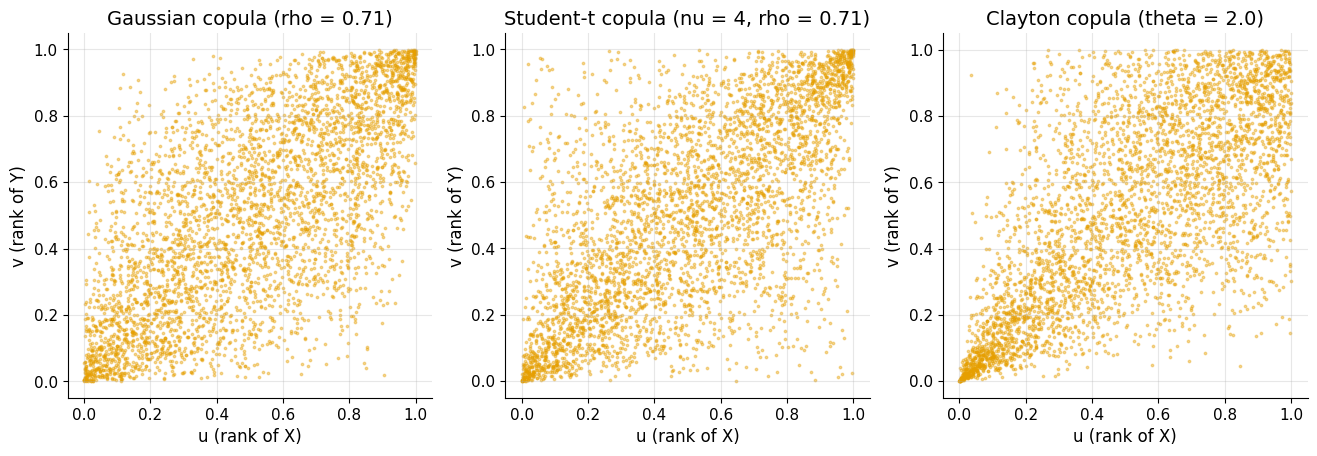

Gaussian  Kendall tau = 0.487
t         Kendall tau = 0.488
Clayton   Kendall tau = 0.511


In [2]:
n = 4000
tau = 0.5
rho = np.sin(np.pi * tau / 2)                                       # Gaussian / t copula parameter giving this Kendall tau
theta = 2 * tau / (1 - tau)                                         # Clayton parameter for this Kendall tau

z = rng.multivariate_normal([0, 0], [[1, rho], [rho, 1]], size=n)
gaussian_uv = stats.norm.cdf(z)

nu = 4
w = rng.chisquare(nu, size=n) / nu
t_draw = z / np.sqrt(w)[:, None]
t_uv = stats.t(nu).cdf(t_draw)

u, q = rng.uniform(size=n), rng.uniform(size=n)                    # Clayton by the conditional method
clayton_uv = np.column_stack([u, (u ** (-theta) * (q ** (-theta / (1 + theta)) - 1) + 1) ** (-1 / theta)])

fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, uv, name in zip(axes, [gaussian_uv, t_uv, clayton_uv], [f"Gaussian copula (rho = {rho:.2f})", f"Student-t copula (nu = 4, rho = {rho:.2f})", f"Clayton copula (theta = {theta:.1f})"]):
    ax.scatter(uv[:, 0], uv[:, 1], s=3, alpha=0.4, color=SIM)
    ax.set_title(name)
    ax.set_xlabel("u (rank of X)")
    ax.set_ylabel("v (rank of Y)")
    ax.set_aspect("equal")
plt.show()
for name, uv in [("Gaussian", gaussian_uv), ("t", t_uv), ("Clayton", clayton_uv)]:
    print(f"{name:9s} Kendall tau = {stats.kendalltau(uv[:, 0], uv[:, 1])[0]:.3f}")

### 7.2 Gluing marginals to a copula
The same Gaussian copula applied to different marginals gives different joint shapes but the same ranks (and the same Kendall tau). Below: Normal, Exponential and Lognormal marginals.

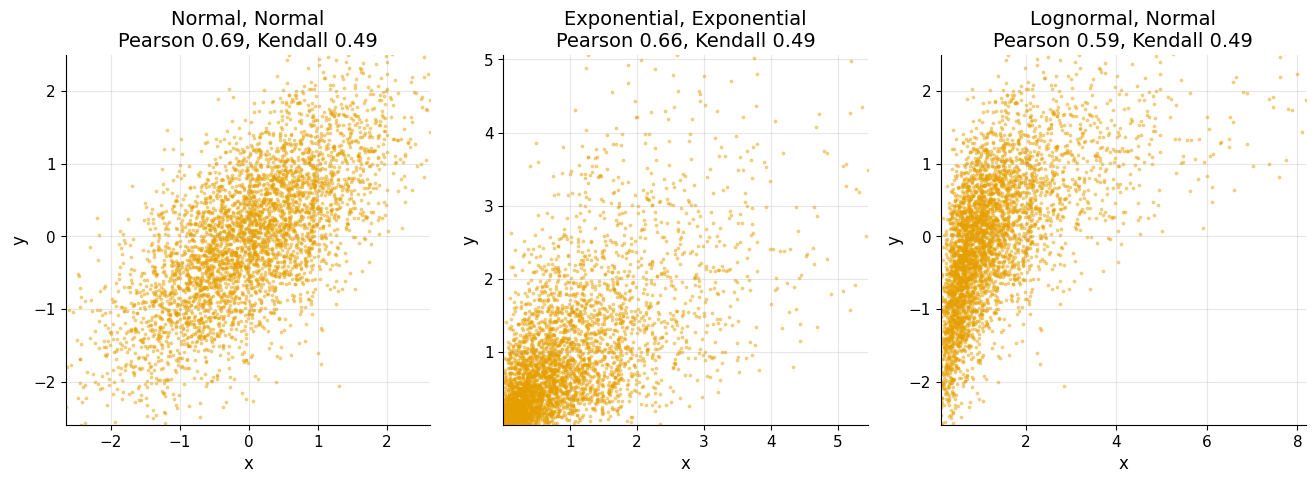

In [3]:
marginal_pairs = [("Normal, Normal", stats.norm(), stats.norm()), ("Exponential, Exponential", stats.expon(), stats.expon()), ("Lognormal, Normal", stats.lognorm(0.8), stats.norm())]
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, (name, fx, fy) in zip(axes, marginal_pairs):
    x, y = fx.ppf(gaussian_uv[:, 0]), fy.ppf(gaussian_uv[:, 1])                  # X = F^-1(U), Y = G^-1(V)
    ax.scatter(x, y, s=3, alpha=0.4, color=SIM)
    ax.set_title(f"{name}\nPearson {np.corrcoef(x, y)[0, 1]:.2f}, Kendall {stats.kendalltau(x, y)[0]:.2f}")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_xlim(np.percentile(x, 0.5), np.percentile(x, 99.5)); ax.set_ylim(np.percentile(y, 0.5), np.percentile(y, 99.5))
plt.show()

### 7.3 Tail dependence: how often are both variables extreme together?
We estimate P(V below q given U below q) as q shrinks. The Gaussian copula's curve falls to 0; the t and Clayton curves level off (positive tail dependence).

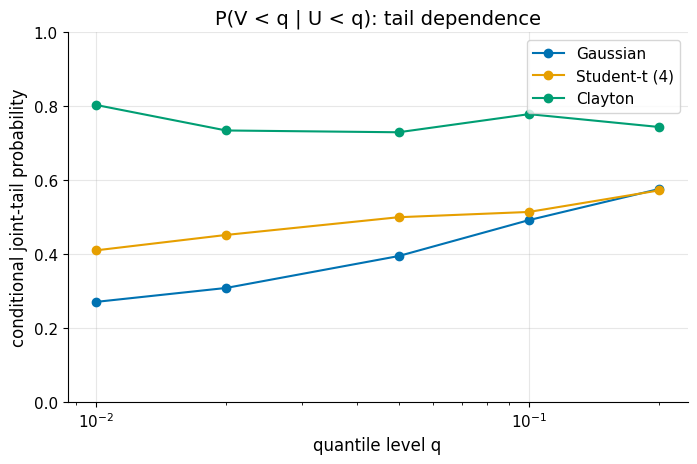

In [4]:
q_values = np.array([0.2, 0.1, 0.05, 0.02, 0.01])
fig, ax = plt.subplots(figsize=(8, 4.8))
for uv, name, color in [(gaussian_uv, "Gaussian", COLORS[0]), (t_uv, "Student-t (4)", COLORS[1]), (clayton_uv, "Clayton", COLORS[2])]:
    big = np.vstack([uv] * 1)
    estimates = [np.mean((big[:, 1] < q) & (big[:, 0] < q)) / np.mean(big[:, 0] < q) for q in q_values]
    ax.plot(q_values, estimates, "o-", color=color, label=name)
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_title("P(V < q | U < q): tail dependence")
ax.set_xlabel("quantile level q")
ax.set_ylabel("conditional joint-tail probability")
ax.legend()
plt.show()

## 8. 3D visuals

### 8.1 Static: the Gaussian copula density
The density of the copula on the unit square for several rho: a flat sheet for rho = 0, and ridges along the diagonal (peaks in the corners) as rho grows.

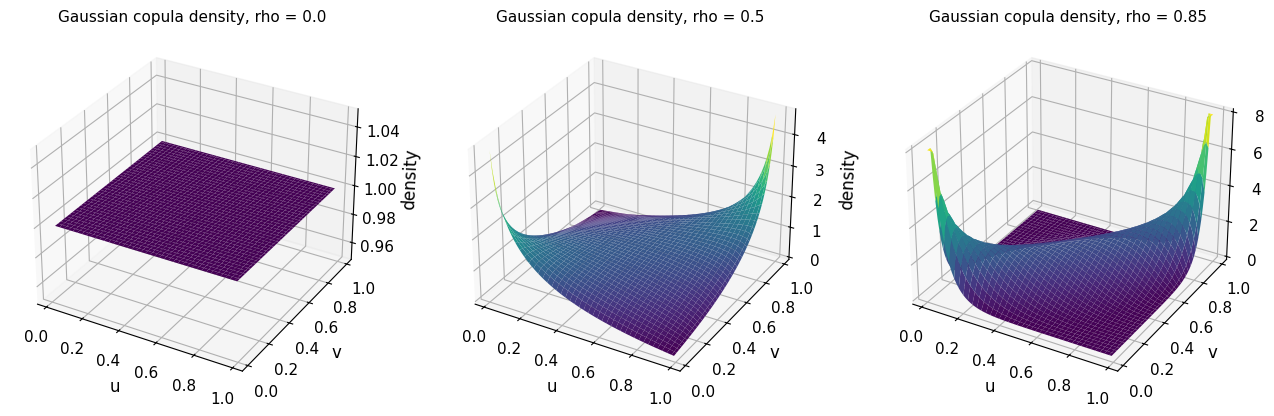

In [5]:
def gaussian_copula_density(u, v, rho):
    """Density c(u, v) of the Gaussian copula."""
    a, b = stats.norm.ppf(u), stats.norm.ppf(v)
    return np.exp(-(rho**2 * (a**2 + b**2) - 2 * rho * a * b) / (2 * (1 - rho**2))) / np.sqrt(1 - rho**2)

grid = np.linspace(0.02, 0.98, 80)
U, V = np.meshgrid(grid, grid)
fig = plt.figure(figsize=(16, 5))
for position, rho_value in enumerate([0.0, 0.5, 0.85], start=1):
    ax = fig.add_subplot(1, 3, position, projection="3d")
    ax.plot_surface(U, V, np.minimum(gaussian_copula_density(U, V, rho_value), 8), cmap="viridis", edgecolor="none")
    ax.set_title(f"Gaussian copula density, rho = {rho_value}", fontsize=11)
    ax.set_xlabel("u"); ax.set_ylabel("v"); ax.set_zlabel("density")
    ax.view_init(elev=30, azim=-60)
plt.show()

### 8.2 Static: the copula CDF as a surface and the independence copula
The Clayton copula CDF compared with the independence copula uv: the gap is the positive dependence.

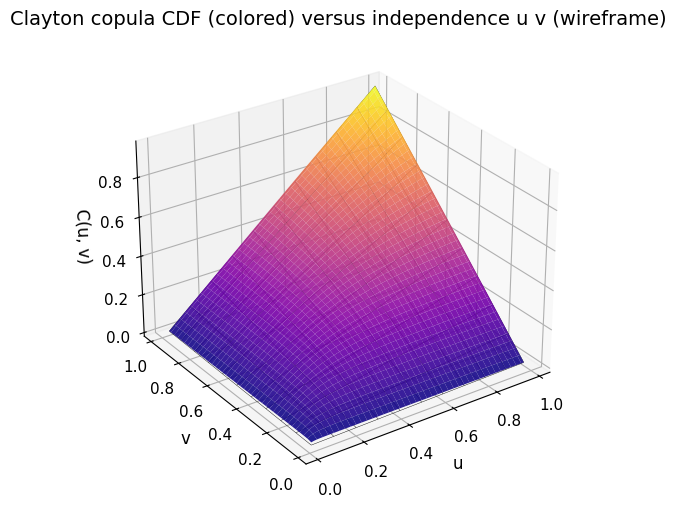

In [6]:
clayton_cdf = (U ** (-theta) + V ** (-theta) - 1) ** (-1 / theta)
fig = plt.figure(figsize=(8, 6))
ax = fig.add_subplot(projection="3d")
ax.plot_surface(U, V, clayton_cdf, cmap="plasma", edgecolor="none", alpha=0.9)
ax.plot_wireframe(U, V, U * V, color="black", linewidth=0.3, rstride=8, cstride=8)
ax.set_title("Clayton copula CDF (colored) versus independence u v (wireframe)")
ax.set_xlabel("u")
ax.set_ylabel("v")
ax.set_zlabel("C(u, v)")
ax.view_init(elev=28, azim=-125)
plt.show()

### 8.3 Interactive Plotly version of the Gaussian copula density (rho = 0.85)

In [7]:
fig = go.Figure(go.Surface(x=grid, y=grid, z=np.minimum(gaussian_copula_density(U, V, 0.85), 8), colorscale="Viridis"))
fig.update_layout(title="Gaussian copula density, rho = 0.85", width=750, height=550, scene=dict(xaxis_title="u", yaxis_title="v", zaxis_title="density"))
fig.show()

## 9. Simulation vs theory

### 9.1 Rank correlations of the Gaussian copula
For rho = 0.7 theory gives Kendall tau = (2/pi) arcsin(0.7) and Spearman = (6/pi) arcsin(0.35).

In [8]:
rho_g = 0.7
z = rng.multivariate_normal([0, 0], [[1, rho_g], [rho_g, 1]], size=100_000)
u_g = stats.norm.cdf(z)
tau_theory = 2 / np.pi * np.arcsin(rho_g)
spearman_theory = 6 / np.pi * np.arcsin(rho_g / 2)
print(f"Kendall tau: theory {tau_theory:.4f}, simulated {stats.kendalltau(u_g[:20_000, 0], u_g[:20_000, 1])[0]:.4f}")
print(f"Spearman:    theory {spearman_theory:.4f}, simulated {stats.spearmanr(u_g[:, 0], u_g[:, 1])[0]:.4f}")
print(f"marginals are uniform: KS p-values {stats.kstest(u_g[:, 0], 'uniform').pvalue:.3f}, {stats.kstest(u_g[:, 1], 'uniform').pvalue:.3f}")

Kendall tau: theory 0.4936, simulated 0.4959
Spearman:    theory 0.6829, simulated 0.6859
marginals are uniform: KS p-values 0.478, 0.626


### 9.2 Pearson correlation depends on the marginals, rank correlation does not

In [9]:
x_exp, y_exp = stats.expon().ppf(u_g[:, 0]), stats.expon().ppf(u_g[:, 1])
x_lognormal, y_lognormal = stats.lognorm(1.0).ppf(u_g[:, 0]), stats.lognorm(1.0).ppf(u_g[:, 1])
table = pd.DataFrame({"marginals": ["Normal", "Exponential", "Lognormal (sigma = 1)"],
                      "Pearson": [np.corrcoef(z[:, 0], z[:, 1])[0, 1], np.corrcoef(x_exp, y_exp)[0, 1], np.corrcoef(x_lognormal, y_lognormal)[0, 1]],
                      "Spearman": [stats.spearmanr(z[:, 0], z[:, 1])[0], stats.spearmanr(x_exp, y_exp)[0], stats.spearmanr(x_lognormal, y_lognormal)[0]]})
print(table.round(3).to_string(index=False))

            marginals  Pearson  Spearman
               Normal    0.703     0.686
          Exponential    0.662     0.686
Lognormal (sigma = 1)    0.599     0.686


## 10. `scipy.stats` cheat sheet

`scipy` has no general copula class (recent versions have `stats.qmc` and `stats.multivariate_t`), but the building blocks are simple: `norm.cdf` / `norm.ppf`, `multivariate_normal`, `multivariate_t`, and the `.ppf` of any marginal.

In [10]:
mvn = stats.multivariate_normal([0, 0], [[1, 0.6], [0.6, 1]])
print("Gaussian copula C(0.1, 0.1) = Phi_rho(Phi^-1(0.1), Phi^-1(0.1)) =", round(mvn.cdf([stats.norm.ppf(0.1)] * 2), 4), " (independence would give 0.01)")
mvt = stats.multivariate_t([0, 0], [[1, 0.6], [0.6, 1]], df=4)
print("t copula uses the bivariate t CDF:", round(mvt.cdf([stats.t(4).ppf(0.1)] * 2), 4))
print("Kendall tau of the Gaussian copula, rho = 0.6:", round(2 / np.pi * np.arcsin(0.6), 4))
print("pseudo-observations (ranks / (n + 1)):", (stats.rankdata([3.2, 1.1, 7.5, 2.0]) / 5).round(2))
print("Spearman and Kendall of a monotone transform are unchanged:", round(stats.spearmanr(z[:2000, 0], z[:2000, 1])[0], 4), round(stats.spearmanr(np.exp(z[:2000, 0]), np.exp(z[:2000, 1]))[0], 4))

Gaussian copula C(0.1, 0.1) = Phi_rho(Phi^-1(0.1), Phi^-1(0.1)) = 0.039  (independence would give 0.01)
t copula uses the bivariate t CDF: 0.0446
Kendall tau of the Gaussian copula, rho = 0.6: 0.4097
pseudo-observations (ranks / (n + 1)): [0.6 0.2 0.8 0.4]
Spearman and Kendall of a monotone transform are unchanged: 0.7008 0.7008


## 11. Real-world worked example: two correlated asset returns

**Scenario (illustrative numbers).** Daily returns: asset A is Normal with mean 0.05 % and SD 1 %; asset B is Normal with mean 0.04 % and SD 1.5 %. Their dependence is modelled by a copula with rank parameter $\rho=0.6$. A **bad day** means both fall by more than 2 %.

**Questions**
1. What is the probability that each asset falls by more than 2 % on its own?
2. What is the probability of a **joint bad day** if the assets were independent, and with the **Gaussian copula** ($\rho=0.6$)?
3. Replacing the Gaussian copula by a **Student-t copula** (4 d.f., same $\rho$, same marginals), how much more likely is a joint bad day?

### 11.1 By hand
**Q1.** $P(A<-2\%)=\Phi\big(\frac{-0.02-0.0005}{0.01}\big)=\Phi(-2.05)=0.0202$; $P(B<-2\%)=\Phi\big(\frac{-0.02-0.0004}{0.015}\big)=\Phi(-1.36)=0.0869$.

**Q2.** Independence: $0.0202\times0.0869=0.00176$ (about 1 day in 570). Gaussian copula: since the marginals are Normal, the joint is a bivariate Normal with correlation 0.6, so $P=\Phi_{0.6}(-2.05,-1.36)=\iint f$; we integrate the bivariate density with the trapezoid rule in plain loops below.

**Q3.** The t-copula has no simple closed form here; we estimate it by simulation and compare with the Gaussian value.

In [11]:
import math

mean_a, sd_a, mean_b, sd_b, rho_assets = 0.0005, 0.01, 0.0004, 0.015, 0.6
z_a = (-0.02 - mean_a) / sd_a
z_b = (-0.02 - mean_b) / sd_b

def standard_normal_cdf(value):
    return 0.5 * (1 + math.erf(value / math.sqrt(2)))

p_a_hand, p_b_hand = standard_normal_cdf(z_a), standard_normal_cdf(z_b)
p_independent_hand = p_a_hand * p_b_hand

def bivariate_normal_density(x, y, r):
    return math.exp(-(x * x - 2 * r * x * y + y * y) / (2 * (1 - r * r))) / (2 * math.pi * math.sqrt(1 - r * r))

# P(Z1 < z_a, Z2 < z_b): trapezoid rule over [-7, z_a] x [-7, z_b] in plain loops
steps = 400
step_x, step_y = (z_a + 7) / steps, (z_b + 7) / steps
p_gaussian_hand = 0.0
for i in range(steps + 1):
    for j in range(steps + 1):
        weight = (0.5 if i in (0, steps) else 1.0) * (0.5 if j in (0, steps) else 1.0)
        p_gaussian_hand += weight * bivariate_normal_density(-7 + i * step_x, -7 + j * step_y, rho_assets)
p_gaussian_hand *= step_x * step_y
print(f"P(A < -2%) = {p_a_hand:.4f}, P(B < -2%) = {p_b_hand:.4f}; independent joint = {p_independent_hand:.5f}; Gaussian-copula joint = {p_gaussian_hand:.5f}")

P(A < -2%) = 0.0202, P(B < -2%) = 0.0869; independent joint = 0.00175; Gaussian-copula joint = 0.01095


### 11.2 In code with `scipy`, and the asserts

In [12]:
marginal_a, marginal_b = stats.norm(mean_a, sd_a), stats.norm(mean_b, sd_b)
p_a_code, p_b_code = marginal_a.cdf(-0.02), marginal_b.cdf(-0.02)
copula_cdf = stats.multivariate_normal([0, 0], [[1, rho_assets], [rho_assets, 1]]).cdf([stats.norm.ppf(p_a_code), stats.norm.ppf(p_b_code)])    # C(F(x), G(y))

assert np.isclose(p_a_hand, p_a_code) and np.isclose(p_b_hand, p_b_code)
assert np.isclose(p_gaussian_hand, copula_cdf, rtol=0.01)
print(f"C(F(-2%), G(-2%)) via scipy = {copula_cdf:.5f}; ratio to independence: {copula_cdf / (p_a_code * p_b_code):.2f}")

C(F(-2%), G(-2%)) via scipy = 0.01095; ratio to independence: 6.24


### 11.3 Verify by simulation and compute the t-copula answer

In [13]:
n_sim = 3_000_000
corr = np.array([[1, rho_assets], [rho_assets, 1]])
z_norm = rng.multivariate_normal([0, 0], corr, size=n_sim)
u_gauss = stats.norm.cdf(z_norm)
chi = rng.chisquare(4, size=n_sim) / 4
u_t = stats.t(4).cdf(rng.multivariate_normal([0, 0], corr, size=n_sim) / np.sqrt(chi)[:, None])

returns_gauss = np.column_stack([marginal_a.ppf(u_gauss[:, 0]), marginal_b.ppf(u_gauss[:, 1])])
returns_t = np.column_stack([marginal_a.ppf(u_t[:, 0]), marginal_b.ppf(u_t[:, 1])])
bad_gauss = np.mean((returns_gauss < -0.02).all(axis=1))
bad_t = np.mean((returns_t < -0.02).all(axis=1))
print(f"marginals check (t copula): P(A < -2%) = {np.mean(returns_t[:, 0] < -0.02):.4f}, P(B < -2%) = {np.mean(returns_t[:, 1] < -0.02):.4f} (same marginals as before)")
print(f"joint bad day: independent {p_independent_hand:.5f} | Gaussian copula exact {copula_cdf:.5f}, simulated {bad_gauss:.5f} | t copula simulated {bad_t:.5f}")
print(f"the t copula makes a joint bad day {bad_t / bad_gauss:.2f} times as likely as the Gaussian copula and {bad_t / p_independent_hand:.1f} times the independent value")
assert abs(bad_gauss - copula_cdf) < 0.0004
assert bad_t > bad_gauss

marginals check (t copula): P(A < -2%) = 0.0201, P(B < -2%) = 0.0869 (same marginals as before)
joint bad day: independent 0.00175 | Gaussian copula exact 0.01095, simulated 0.01096 | t copula simulated 0.01323
the t copula makes a joint bad day 1.21 times as likely as the Gaussian copula and 7.5 times the independent value


### 11.4 Plots

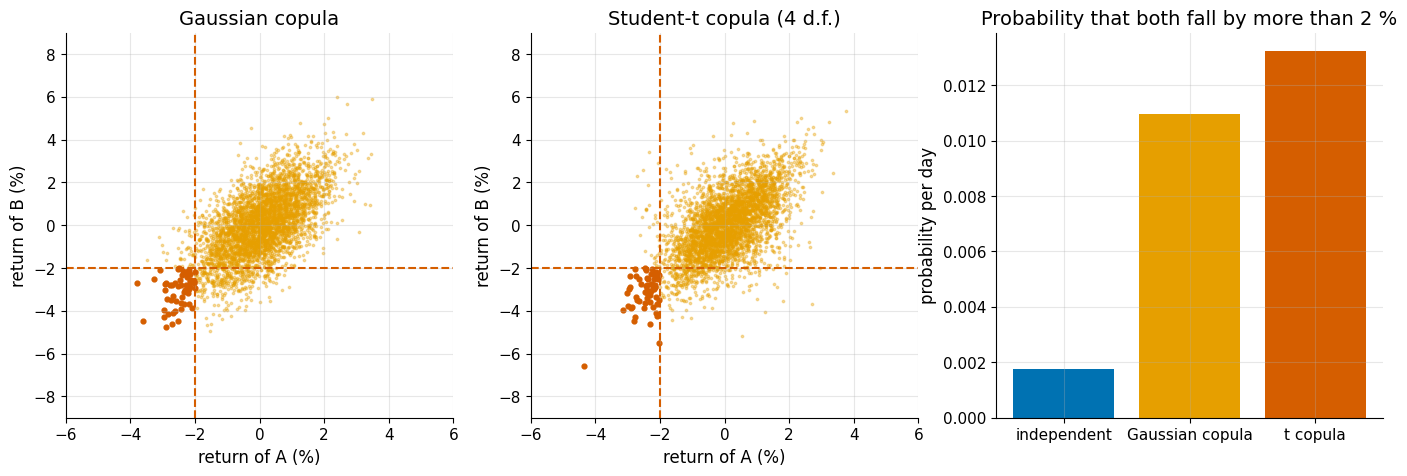

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sample = slice(0, 4000)
for ax, returns, name in [(axes[0], returns_gauss, "Gaussian copula"), (axes[1], returns_t, "Student-t copula (4 d.f.)")]:
    ax.scatter(returns[sample, 0] * 100, returns[sample, 1] * 100, s=3, alpha=0.35, color=SIM)
    ax.axvline(-2, color=HIGHLIGHT, linestyle="--")
    ax.axhline(-2, color=HIGHLIGHT, linestyle="--")
    both = (returns[sample, 0] < -0.02) & (returns[sample, 1] < -0.02)
    ax.scatter(returns[sample][both, 0] * 100, returns[sample][both, 1] * 100, s=12, color=HIGHLIGHT)
    ax.set_title(name)
    ax.set_xlabel("return of A (%)")
    ax.set_ylabel("return of B (%)")
    ax.set_xlim(-6, 6); ax.set_ylim(-9, 9)
axes[2].bar(["independent", "Gaussian copula", "t copula"], [p_independent_hand, bad_gauss, bad_t], color=[COLORS[0], COLORS[1], HIGHLIGHT])
axes[2].set_title("Probability that both fall by more than 2 %")
axes[2].set_ylabel("probability per day")
plt.show()

### 11.5 Interpretation and decision
- On its own, A falls by more than 2 % on about **2 %** of days and B on about **8.7 %** of days.
- If the two were **independent**, a joint bad day would happen on 0.18 % of days (1 in 570). With **positive dependence** (Gaussian copula, rho = 0.6) it is **about 1.1 %** (6.2 times as often).
- A **t copula with the same rank correlation and the same marginals** makes the joint bad day **even more likely** (about 1.3 %, 1.2 times the Gaussian value and 7.5 times the independent one): extremes cluster. The Gaussian copula **understates joint tail risk**.
- **Decision:** for stress testing and capital reserves, do not rely on a Gaussian copula; compare with a t or Clayton copula, and base the buffer on the heavier-tailed result.

### 11.6 Extra example: correlated waiting times (Exponential marginals)
Two queues have Exponential waiting times with means 10 and 20 minutes. A Gaussian copula with parameter 0.7 ties them. What are the Pearson, Spearman and Kendall correlations?

In [15]:
rho_q = 0.7
z_q = rng.multivariate_normal([0, 0], [[1, rho_q], [rho_q, 1]], size=300_000)
u_q = stats.norm.cdf(z_q)
wait1, wait2 = stats.expon(scale=10).ppf(u_q[:, 0]), stats.expon(scale=20).ppf(u_q[:, 1])
spearman_hand, tau_hand = 6 / np.pi * np.arcsin(rho_q / 2), 2 / np.pi * np.arcsin(rho_q)
print(f"Pearson {np.corrcoef(wait1, wait2)[0, 1]:.3f} (below {rho_q} because of the skewed marginals)")
print(f"Spearman {stats.spearmanr(wait1, wait2)[0]:.3f} (theory {spearman_hand:.3f}); Kendall {stats.kendalltau(wait1[:30_000], wait2[:30_000])[0]:.3f} (theory {tau_hand:.3f})")
print(f"marginal means {wait1.mean():.2f}, {wait2.mean():.2f} (10, 20); P(both wait more than 30 min) = {np.mean((wait1 > 30) & (wait2 > 30)):.4f} vs independent {np.exp(-3) * np.exp(-1.5):.4f}")
assert abs(stats.spearmanr(wait1, wait2)[0] - spearman_hand) < 0.005

Pearson 0.662 (below 0.7 because of the skewed marginals)
Spearman 0.683 (theory 0.683); Kendall 0.496 (theory 0.494)
marginal means 10.01, 20.03 (10, 20); P(both wait more than 30 min) = 0.0412 vs independent 0.0111


**Interpretation.** The rank correlations match the copula theory exactly, while the **Pearson correlation is lower (about 0.66)** because the Exponential marginals are skewed: Pearson mixes the marginals with the dependence. This is why copula parameters and rank correlations are the clean way to describe dependence. Both queues waiting more than 30 minutes is about 3.7 times as likely as under independence (4.1 % versus 1.1 %).

## 12. Where it is used

### Statistics
- **Multivariate modelling with non-Normal marginals,** dependence measures that do not depend on the marginals (Kendall's tau, Spearman), semiparametric copula models.

### Data science
- **Risk management and finance:** joint default and portfolio loss models, stress testing, insurance pooling; **synthetic data generation** that keeps both the marginals and the dependence (the Gaussian copula is used in tabular data synthesizers).

### ML and AI
- **Copula-based generative models** and tabular synthesizers, **normalizing flows** (the copula separates marginals from dependence), and uncertainty modelling for multivariate predictions; rank-based correlation for robust feature analysis.

## 13. Common pitfalls and misconceptions

- **Same correlation does not mean same risk:** Gaussian, t and Clayton copulas with equal Kendall's tau have very different joint tails.
- **Pearson correlation is not a copula parameter:** it changes with the marginals; use Kendall or Spearman, or the copula parameter.
- **The Gaussian copula has zero tail dependence:** it understates simultaneous extreme events, whatever the correlation.
- **Normal marginals plus Gaussian copula is the only case equal to the multivariate Normal.**
- **A copula says nothing about the marginals:** fit them separately and check each.
- **Discrete marginals break uniqueness:** Sklar's copula is not unique with ties (use care with count data).

## 14. Exercises

1. For a Gaussian copula with $\rho=0.5$, compute Kendall's $\tau$ and Spearman's $\rho_S$.
2. A Clayton copula has $\theta=2$. Find its lower-tail dependence $\lambda_L$ and Kendall's $\tau=\theta/(\theta+2)$.
3. Using the independence copula, find the probability that two assets with marginal loss probabilities 5 % and 10 % both lose on the same day. What is the maximum possible (comonotone) value?
4. Apply a Gaussian copula with $\rho=0.8$ to two Uniform(0,10) marginals. What is the Pearson correlation of $(X,Y)$? (Hint: simulate.)
5. (Harder) Show that Kendall's $\tau$ and Spearman's $\rho_S$ are unchanged if $X$ is replaced by $e^X$.

Solutions are at the end.

## 15. Summary table

| Item | Formula |
|---|---|
| Sklar | H(x, y) = C(F(x), G(y)) |
| Sampling | (U, V) ~ C, then X = F^-1(U), Y = G^-1(V) |
| Gaussian copula | Phi_rho(Phi^-1(u), Phi^-1(v)); tau = (2/pi) arcsin rho |
| Spearman (Gaussian) | (6/pi) arcsin(rho / 2) |
| t copula tail dependence | 2 t_(nu+1)(-sqrt((nu + 1)(1 - rho)/(1 + rho))) |
| Clayton | (u^-theta + v^-theta - 1)^(-1/theta); lower tail 2^(-1/theta); tau = theta/(theta + 2) |
| Independence / comonotone | u v / min(u, v) |

## Solutions

In [16]:
print("1: tau =", round(2 / np.pi * np.arcsin(0.5), 4), " Spearman =", round(6 / np.pi * np.arcsin(0.25), 4))
print("2: lambda_L =", round(2 ** (-1 / 2), 4), " tau =", 2 / (2 + 2))
print("3: independent =", 0.05 * 0.10, " comonotone maximum =", min(0.05, 0.10))
zz = rng.multivariate_normal([0, 0], [[1, 0.8], [0.8, 1]], size=300_000)
uu = stats.norm.cdf(zz) * 10
print("4: Pearson of the two Uniform(0, 10) variables:", round(np.corrcoef(uu[:, 0], uu[:, 1])[0, 1], 4), "(= (6/pi) arcsin(0.4) =", round(6 / np.pi * np.arcsin(0.4), 4), ")")
print("5: Spearman before / after exp:", round(stats.spearmanr(zz[:50_000, 0], zz[:50_000, 1])[0], 4), round(stats.spearmanr(np.exp(zz[:50_000, 0]), np.exp(zz[:50_000, 1]))[0], 4))

1: tau = 0.3333  Spearman = 0.4826
2: lambda_L = 0.7071  tau = 0.5
3: independent = 0.005000000000000001  comonotone maximum = 0.05


4: Pearson of the two Uniform(0, 10) variables: 0.7855 (= (6/pi) arcsin(0.4) = 0.7859 )
5: Spearman before / after exp: 0.7847 0.7847


**1.** $\tau=\frac2\pi\arcsin0.5=\frac13=0.333$; $\rho_S=\frac6\pi\arcsin0.25=0.483$.

**2.** $\lambda_L=2^{-1/2}=0.707$; $\tau=\frac2{4}=0.5$.

**3.** Independent: $0.05\times0.10=0.005$; the largest possible joint probability is $\min(0.05,0.10)=0.05$ (comonotone: the 5 % worst days of A are all among the 10 % worst of B).

**4.** The uniform marginals make Pearson equal to Spearman: $\frac6\pi\arcsin(0.4)=0.786$.

**5.** Ranks are unchanged by an increasing transformation, so both rank correlations are identical before and after (printed).